# Results: AI governance registry with deployment gates

Evidence for both required components:

1. **Responsible AI.** The gate's decisions on the three example models, and the fairness numbers it recomputes from evidence.
2. **Big data.** Scaling of the same Spark fairness audit, from 1.6 M to 25 M rows and from 1 to 8 cores, against single-process pandas.

Run `make train benchmark` first, then `make notebook` to re-execute this notebook.

In [1]:
import json, os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

BLUE, ORANGE = "#2a78d6", "#eb6834"   # validated categorical slots 1-2 (dataviz reference palette)
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10})
RACE = {1: "White", 2: "Black", 3: "Am. Indian", 4: "Alaska Native", 5: "AIAN tribe", 6: "Asian",
        7: "NH / Pac. Isl.", 8: "Other race", 9: "Two or more"}

## 1. Gate decisions

This runs the same function CI runs, `governance.gate.check_model`, on every registered model.

In [2]:
from governance import gate
policy = gate.load("registry/policy.yaml")
datasets = {p.stem: gate.load(p) for p in Path("registry/datasets").glob("*.yaml")}
from governance.fairness import spark
results = [gate.check_model(d, policy, datasets, spark) for d in sorted(Path("registry/models").iterdir())]
decisions = pd.DataFrame([{"model": r["id"], "tier": r["tier"], **r["status"],
                           "decision": "DEPLOY" if r["deployable"] else "BLOCKED"} for r in results])
decisions

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/03 17:17:40 WARN Utils: Your hostname, Dhanushs-MacBook-Air-5.local, resolves to a loopback address: 127.0.0.1; using 10.211.118.157 instead (on interface en0)
26/11/03 17:17:40 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/03 17:17:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


,model,tier,risk,documentation,lineage,fairness,approval,decision
0,income-baseline,high,pass,pass,pass,fail,pass,BLOCKED
1,income-fair,high,pass,pass,pass,pass,pass,DEPLOY
2,taxi-eta,minimal,pass,fail,fail,n/a,n/a,BLOCKED


In [3]:
for r in results:
    issues = [f"{g}: {m}" for g in gate.GATES for m in r["fails"][g]]
    print(f"{r['id']}:", "no blocking issues" if not issues else "")
    for i in issues:
        print("   -", i)

income-baseline: 
   - fairness: `RAC1P` disparate impact 0.299 < 0.8
   - fairness: `RAC1P` equal-opportunity gap 0.331 > 0.1
income-fair: no blocking issues
taxi-eta: 
   - documentation: schema: `(root)` Additional properties are not allowed ('known_issues' was unexpected)
   - documentation: missing `limitations`
   - lineage: dataset `nyc-tlc-yellow-2023-01` missing `personal_data`


## 2. Fairness: what the gate measured

The numbers come from `eval_predictions.parquet` (the California hold-out set, 39,133 people). Groups with fewer than 100 people are not gated on.

In [4]:
rows = []
for mid in ["income-baseline", "income-fair"]:
    p = pd.read_parquet(f"registry/models/{mid}/eval_predictions.parquet")
    r = next(r for r in results if r["id"] == mid)
    rows.append({"model": mid, "accuracy": accuracy_score(p.y_true, p.y_pred),
                 "DI SEX": r["fairness"]["SEX"]["disparate_impact"],
                 "DI RAC1P": r["fairness"]["RAC1P"]["disparate_impact"],
                 "TPR gap SEX": r["fairness"]["SEX"]["equal_opportunity_diff"],
                 "TPR gap RAC1P": r["fairness"]["RAC1P"]["equal_opportunity_diff"]})
tradeoff = pd.DataFrame(rows).set_index("model").round(3)
tradeoff

,accuracy,DI SEX,DI RAC1P,TPR gap SEX,TPR gap RAC1P
model,,,,,
income-baseline,0.825,0.802,0.299,0.015,0.331
income-fair,0.747,0.977,0.885,0.075,0.054


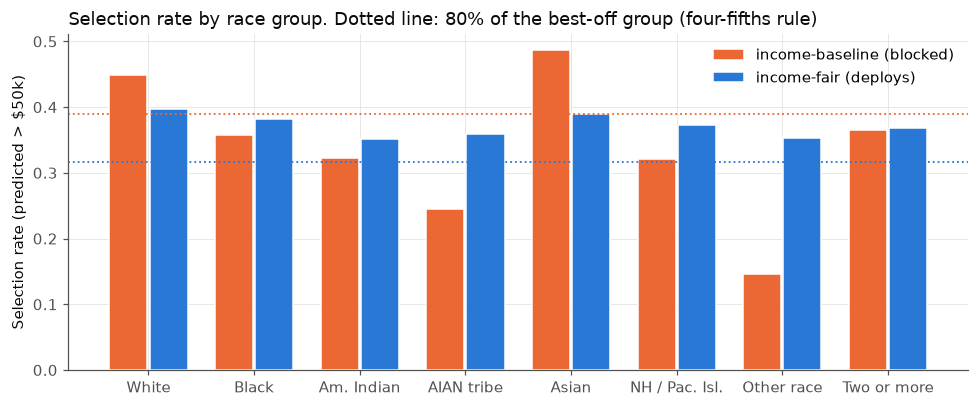

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
groups = None
for i, (mid, color, label) in enumerate([("income-baseline", ORANGE, "income-baseline (blocked)"),
                                          ("income-fair", BLUE, "income-fair (deploys)")]):
    g = pd.DataFrame(next(r for r in results if r["id"] == mid)["fairness"]["RAC1P"]["groups"])
    g = g[g.n >= 100].sort_values("RAC1P")
    groups = g.RAC1P.map(RACE).tolist()
    x = [j + (i - 0.5) * 0.38 for j in range(len(g))]
    ax.bar(x, g.selection_rate, width=0.36, color=color, label=label, edgecolor="white", linewidth=1)
    ax.axhline(0.8 * g.selection_rate.max(), color=color, linestyle=":", linewidth=1.2)
ax.set_xticks(range(len(groups)), groups, rotation=0)
ax.set_ylabel("Selection rate (predicted > $50k)")
ax.set_title("Selection rate by race group. Dotted line: 80% of the best-off group (four-fifths rule)", loc="left", color=INK)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("results/fig_selection_rates.png", dpi=150)

**Reading.** Dropping SEX and RAC1P as inputs ("fairness through unawareness") is not enough. Through proxies such as occupation and place of birth, the baseline selects the "Other race" group at 0.146, against 0.487 for Asian respondents (disparate impact 0.30). The constrained model narrows every group to 0.35–0.40 (disparate impact 0.89). The cost is 7.8 accuracy points, and the gate makes that trade-off explicit instead of leaving it to a reviewer's judgement.

## 3. Big data: scaling the fairness audit

The benchmark scores every row with the model and computes per-group confusion counts with `governance.fairness.group_counts`, the code the CI gate uses. The data is California ACSIncome replicated with new person ids. Each timing is the best of 2 runs; JVM start-up is excluded here and measured separately in §4.

In [6]:
bench = pd.read_csv("results/benchmark.csv")
# Correctness first: every engine and scale must report the same disparate impact.
assert bench.rac1p_disparate_impact.nunique() == 1, bench.rac1p_disparate_impact.unique()
bench

,engine,cores,scale,rows,seconds,rows_per_sec,rac1p_disparate_impact,parquet_mb
0,pandas,1,8,1565320,5.09,307444,0.2938,16.0
1,pandas,1,32,6261280,20.72,302167,0.2938,63.6
2,pandas,1,128,25045120,85.10,294314,0.2938,253.9
3,spark,1,128,25045120,92.00,272235,0.2938,253.9
4,spark,2,128,25045120,47.22,530364,0.2938,253.9
5,spark,4,128,25045120,28.77,870667,0.2938,253.9
6,spark,8,8,1565320,3.72,420270,0.2938,16.0
7,spark,8,32,6261280,5.05,1240981,0.2938,63.6
8,spark,8,128,25045120,19.68,1272681,0.2938,253.9


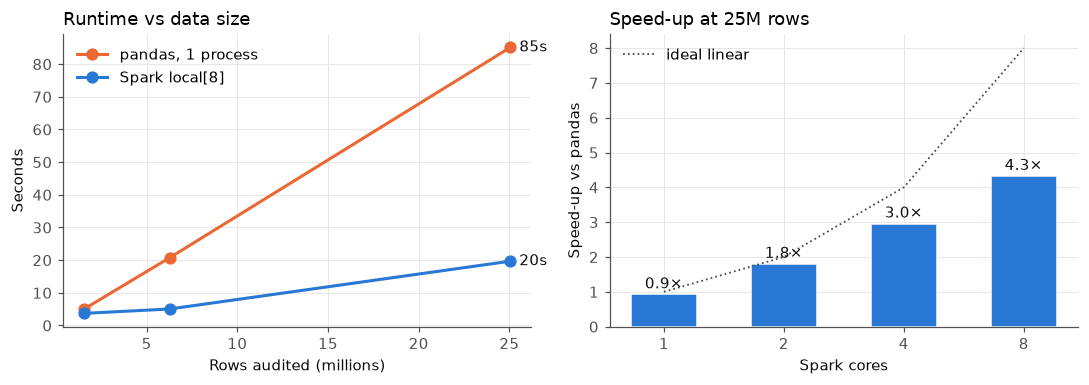

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6))
pdf = bench[bench.engine == "pandas"].sort_values("rows")
sp8 = bench[(bench.engine == "spark") & (bench.cores == bench.cores.max())].sort_values("rows")
for d, color, label in [(pdf, ORANGE, "pandas, 1 process"), (sp8, BLUE, f"Spark local[{bench.cores.max()}]")]:
    a.plot(d.rows / 1e6, d.seconds, color=color, linewidth=2, marker="o", markersize=7, label=label)
    a.annotate(f"{d.seconds.iloc[-1]:.0f}s", (d.rows.iloc[-1] / 1e6, d.seconds.iloc[-1]),
               textcoords="offset points", xytext=(6, 0), va="center", color=INK)
a.set_xlabel("Rows audited (millions)"); a.set_ylabel("Seconds"); a.set_title("Runtime vs data size", loc="left")
a.legend(frameon=False)
big = bench[(bench.engine == "spark") & (bench.rows == bench.rows.max())].sort_values("cores")
base = bench[(bench.engine == "pandas") & (bench.rows == bench.rows.max())].seconds.iloc[0]
speedup = base / big.seconds
b.bar(big.cores.astype(str), speedup, color=BLUE, width=0.55, edgecolor="white")
b.plot(big.cores.astype(str), big.cores, color=MUTED, linestyle=":", linewidth=1.2, label="ideal linear")
for x, s in zip(big.cores.astype(str), speedup):
    b.annotate(f"{s:.1f}×", (x, s), textcoords="offset points", xytext=(0, 4), ha="center", color=INK)
b.set_xlabel("Spark cores"); b.set_ylabel("Speed-up vs pandas")
b.set_title(f"Speed-up at {bench.rows.max()/1e6:.0f}M rows", loc="left"); b.legend(frameon=False)
fig.tight_layout()
fig.savefig("results/fig_scaling.png", dpi=150)

## 4. Cost of the CI gate

Wall-clock time for `python -m governance.gate <model>` on this machine, Spark start-up included. Only high-risk models start Spark.

In [8]:
pd.Series(json.loads(Path("results/gate_timing.json").read_text()), name="seconds").to_frame()

,seconds
income-fair,6.15
income-baseline,4.57
taxi-eta,0.10
